In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve)

import warnings
warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
!gdown 14ErNbVBRNBH8jsNDFuM1RHvUtxJ9BGCT -O Final_Processed_HomeCredit.csv
import pandas as pd
df = pd.read_csv('Final_Processed_HomeCredit.csv')
print(df.shape)

Downloading...
From (original): https://drive.google.com/uc?id=14ErNbVBRNBH8jsNDFuM1RHvUtxJ9BGCT
From (redirected): https://drive.google.com/uc?id=14ErNbVBRNBH8jsNDFuM1RHvUtxJ9BGCT&confirm=t&uuid=1d1e81d8-2d5b-4b48-8d02-cffdd498ee65
To: /content/Final_Processed_HomeCredit.csv
100% 228M/228M [00:03<00:00, 58.0MB/s]
(307507, 138)


In [ ]:
df = pd.read_csv('Final_Processed_HomeCredit.csv')
print(f"Shape: {df.shape}")
print(f"Kolom: {df.shape[1]}")
df.head()

Shape: (307507, 138)
Kolom: 138


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AVG_PREV_CREDIT,MAX_PREV_CREDIT,AVG_CREDIT_APPLICATION_DIFF,AVG_PREV_CREDIT_APPLICATION_RATIO,TOTAL_PREV_APPROVED,TOTAL_PREV_REFUSED,PREV_APPROVAL_RATE,PREV_REFUSED_RATE,APPROVAL_REFUSAL_DIFF,HAS_PREV_REFUSED
0,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,484191.000,1035882.0,48754.5,1.057664,3,0,1.00,0.00,3,0
1,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,166638.750,284400.0,16108.5,1.046356,6,0,1.00,0.00,6,0
2,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,162767.700,501975.0,7065.9,0.782855,4,0,0.80,0.00,4,0
3,100010,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,...,260811.000,260811.0,13599.0,1.055009,1,0,1.00,0.00,1,0
4,100011,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,...,261840.375,732915.0,59107.5,0.518719,3,1,0.75,0.25,2,1


In [ ]:
print(f"Total missing values: {df.isnull().sum().sum()}")

Total missing values: 0


In [ ]:
df = df.drop(columns=['SK_ID_CURR'])

print(f"Shape sekarang: {df.shape}")

Shape sekarang: (307507, 137)


In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Kolom kategorik yang perlu di-encode: {len(cat_cols)}")
print(cat_cols)

Kolom kategorik yang perlu di-encode: 16
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [ ]:
for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

print("Done encoding. Sample:")
df.head()

Done encoding. Sample:


,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,AVG_PREV_CREDIT,MAX_PREV_CREDIT,AVG_CREDIT_APPLICATION_DIFF,AVG_PREV_CREDIT_APPLICATION_RATIO,TOTAL_PREV_APPROVED,TOTAL_PREV_REFUSED,PREV_APPROVAL_RATE,PREV_REFUSED_RATE,APPROVAL_REFUSAL_DIFF,HAS_PREV_REFUSED
0,0,0,0,0,0,0,270000.0,1293502.5,35698.5,1129500.0,...,484191.000,1035882.0,48754.5,1.057664,3,0,1.00,0.00,3,0
1,0,0,1,0,1,0,121500.0,513000.0,21865.5,513000.0,...,166638.750,284400.0,16108.5,1.046356,6,0,1.00,0.00,6,0
2,0,0,1,0,1,0,99000.0,490495.5,27517.5,454500.0,...,162767.700,501975.0,7065.9,0.782855,4,0,0.80,0.00,4,0
3,0,0,1,1,1,0,360000.0,1530000.0,42075.0,1530000.0,...,260811.000,260811.0,13599.0,1.055009,1,0,1.00,0.00,1,0
4,0,0,0,0,1,0,112500.0,1019610.0,33826.5,913500.0,...,261840.375,732915.0,59107.5,0.518719,3,1,0.75,0.25,2,1


In [ ]:
X = df.drop(columns=['TARGET'])
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (246008, 79) | Test: (61503, 79)


In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf.fit(X_train, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   44.6s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  2.5min finished


RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_leaf=10, min_samples_split=20,
                       n_estimators=200, n_jobs=-1, random_state=42, verbose=1)

In [ ]:
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Lunas', 'Default']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    2.8s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    2.9s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.9s


              precision    recall  f1-score   support

       Lunas       0.95      0.84      0.89     56538
     Default       0.20      0.46      0.28      4965

    accuracy                           0.81     61503
   macro avg       0.58      0.65      0.59     61503
weighted avg       0.89      0.81      0.84     61503

ROC-AUC: 0.7400


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    3.0s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    3.0s finished


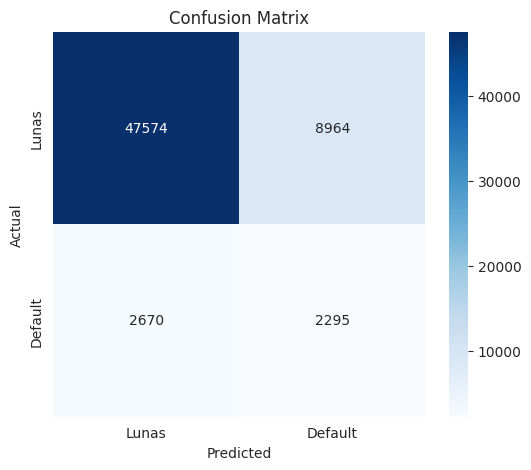

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Lunas', 'Default'],
            yticklabels=['Lunas', 'Default'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

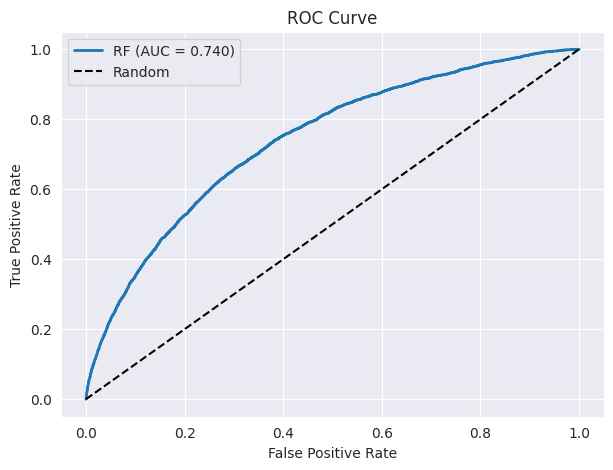

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'RF (AUC = {roc_auc_score(y_test, y_pred_proba):.3f})', linewidth=2)
plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend()
plt.show()

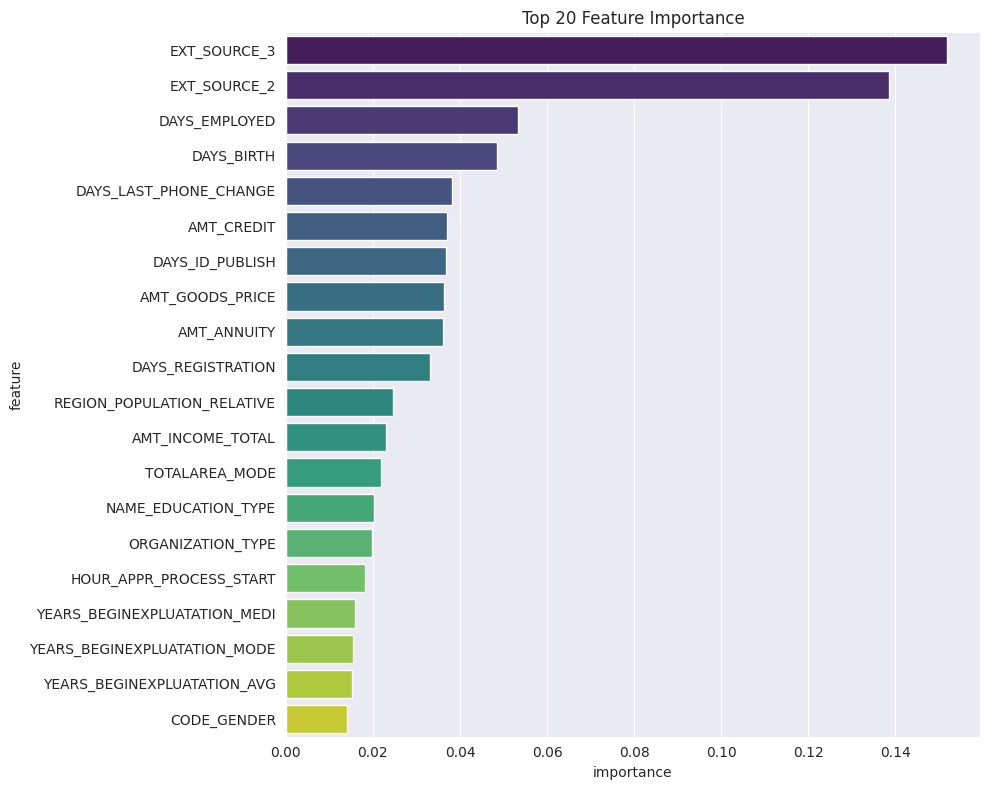

,feature,importance
39,EXT_SOURCE_3,0.151819
38,EXT_SOURCE_2,0.138481
16,DAYS_EMPLOYED,0.053422
15,DAYS_BIRTH,0.048570
52,DAYS_LAST_PHONE_CHANGE,0.038196
6,AMT_CREDIT,0.037018
18,DAYS_ID_PUBLISH,0.036705
8,AMT_GOODS_PRICE,0.036368
7,AMT_ANNUITY,0.036071
17,DAYS_REGISTRATION,0.033152


In [ ]:
feat_imp = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(data=feat_imp.head(20), x='importance', y='feature', palette='viridis')
plt.title('Top 20 Feature Importance')
plt.tight_layout(); plt.show()

feat_imp.head(20)

In [ ]:
import joblib
joblib.dump(rf, 'rf_credit_model.pkl')

from google.colab import files
files.download('rf_credit_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>